# Two-winding transformer: 400 V to 48 V at 200 kHz

This is a PQ4040, current-driven transformer model. The intended drive is a bipolar square wave from a 400 V DC link. The winding stack is 4 primary turns, a rectangular secondary section, 4 primary turns, 4 primary turns, a rectangular secondary section, and 4 primary turns. This gives 16 primary turns and 2 secondary turns, with an ideal turns-ratio voltage of approximately 50 V, close to the 48 V target.

Using an estimated effective core area of 160 mmÂ², the square-wave estimate is approximately B_pk = V_dc / (4 f N_p A_e) = 0.20 T.

The FEM solution below is still a phasor small-signal basis calculation for extracting the inductance matrix; the DC-link waveform is used for the design estimate. The primary turns use round Litz conductors with an impressed current-density model, while the secondary uses solid rectangular foil conductors with a total-current constraint.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

repository_root = Path.cwd()
if not (repository_root / "fem").is_dir():
    repository_root = repository_root.parent
sys.path.insert(0, str(repository_root))

from fem import (
    FrequencyDomainResult,
    build_mesh,
    integrated_current,
    litz_loss,
    meeker_litz_properties,
    magnetic_field_intensity,
    magnetic_flux_density,
    PhysicalField,
    conductor_area,
    solve_combined,
    winding_flux_linkages,
)
from fem.plot import (
    PhysicalField,
)
from example_studies.transformer_2kw import make_pq4040_2kw_transformer

In [2]:
model = make_pq4040_2kw_transformer()
print("Transformer model created with make_pq4040_2kw_transformer()")

mesh = build_mesh(model, max_size=0.001, conductor_size=0.00015)
frequency = 200_000.0
primary_litz_properties = meeker_litz_properties(
    frequency,
    strand_diameter=0.14e-3,
    fill_factor=0.9,
)
v_dc = 400.0
primary_turns = 16
secondary_turns = 2
effective_core_area = 160e-6
estimated_b_peak = v_dc / (4.0 * frequency * primary_turns * effective_core_area)
estimated_secondary_voltage = v_dc * secondary_turns / primary_turns
print(f"Estimated square-wave B peak: {estimated_b_peak:.3f} T")
print(f"Estimated ideal secondary voltage: {estimated_secondary_voltage:.1f} V")
solver_options = {
    "mesh": mesh,
    "frequency": frequency,
    "relative_permeability": {"core": 1500.0},
    "return_voltages": False,
    "litz_properties": {"primary": primary_litz_properties},
}

# Solve once for each unit-current basis vector of the two-winding system.
primary_current_density = 1.0 / conductor_area(mesh, 0)
a_phi_10, densities_10 = solve_combined(
    currents={"primary": 0.0, "secondary": 0.0},
    current_modes={"primary": "fixed_current_density", "secondary": "total_current"},
    fixed_current_density={"primary": primary_current_density}, **solver_options
)
a_phi_01, densities_01 = solve_combined(
    currents={"primary": 0.0, "secondary": 1.0},
    current_modes={"primary": "fixed_current_density", "secondary": "total_current"},
    fixed_current_density={"primary": 0.0}, **solver_options
)
result_10 = FrequencyDomainResult.from_solution(
    model, mesh, a_phi_10, densities_10, frequency_hz=frequency,
)

flux_density_10 = magnetic_flux_density(mesh, a_phi_10)
flux_density_01 = magnetic_flux_density(mesh, a_phi_01)
flux_linkages_10 = winding_flux_linkages(mesh, a_phi_10)
flux_linkages_01 = winding_flux_linkages(mesh, a_phi_01)
flux_density = flux_density_10

print(f"Mesh: {len(mesh.points)} nodes, {len(mesh.triangles)} triangles")
print("Turn currents:")
for name, density in densities_10.items():
    print(f"  {name}: {integrated_current(mesh, density, name):.4g} A")
print(f"Flux linkages for (1, 0) A: {flux_linkages_10}")
print(f"Flux linkages for (0, 1) A: {flux_linkages_01}")
print(f"Maximum |B| for (1, 0) A: {np.max(np.linalg.norm(flux_density_10, axis=1)):.4e} T")
print(f"Maximum |B| for (0, 1) A: {np.max(np.linalg.norm(flux_density_01, axis=1)):.4e} T")

Transformer model created with make_pq4040_2kw_transformer()
Estimated square-wave B peak: 0.195 T
Estimated ideal secondary voltage: 50.0 V
Mesh: 1335 nodes, 2586 triangles
Turn currents:
  conductor_0: 1+0j A
  conductor_1: 1+0j A
  conductor_2: 1+0j A
  conductor_3: 1+0j A
  conductor_4: 1+0j A
  conductor_5: 1+0j A
  conductor_6: 1+0j A
  conductor_7: 1+0j A
  conductor_8: 1+0j A
  conductor_9: 1+0j A
  conductor_10: 1+0j A
  conductor_11: 1+0j A
  conductor_12: 1+0j A
  conductor_13: 1+0j A
  conductor_14: 1+0j A
  conductor_15: 1+0j A
  conductor_16: -1.473e-13+5.238e-12j A
  conductor_17: 5.694e-14+1.728e-11j A
Flux linkages for (1, 0) A: {'primary': np.complex128(0.00011684854310506093-2.105551045942715e-07j), 'secondary': np.complex128(1.4599895167706586e-05-2.7178003076390978e-08j)}
Flux linkages for (0, 1) A: {'primary': np.complex128(1.4598904924505606e-05-2.662348323961583e-08j), 'secondary': np.complex128(1.8339675872080656e-06-3.9393733051443574e-09j)}
Maximum |B| for (1

## Inductance matrix

For each unit-current excitation, the flux-linkage vector is a column of the inductance matrix: `L[i, j] = lambda_i / I_j`. The entries are complex because the frequency-domain solution includes winding eddy-current effects.

In [3]:
winding_order = ["primary", "secondary"]
inductance_matrix = np.array([
    [flux_linkages_10[name] for name in winding_order],
    [flux_linkages_01[name] for name in winding_order],
], dtype=complex).T
print("Inductance matrix [H]:")
print(inductance_matrix)
real_inductance_uH = inductance_matrix.real * 1e6
l11, m_primary, m_secondary, l22 = (
    real_inductance_uH[0, 0],
    real_inductance_uH[0, 1],
    real_inductance_uH[1, 0],
    real_inductance_uH[1, 1],
)
print("Real-valued inductance parameters [uH]:")
print(f"  L11 = {l11:.6f} uH")
print(f"  M   = {(m_primary + m_secondary) / 2:.6f} uH")
print(f"  L22 = {l22:.6f} uH")
print("Real-valued inductance matrix [uH]:")
print(real_inductance_uH)
print(f"Reciprocity error: {abs(inductance_matrix[0, 1] - inductance_matrix[1, 0]):.3e} H")

Inductance matrix [H]:
[[1.16848543e-04-2.10555105e-07j 1.45989049e-05-2.66234832e-08j]
 [1.45998952e-05-2.71780031e-08j 1.83396759e-06-3.93937331e-09j]]
Real-valued inductance parameters [uH]:
  L11 = 116.848543 uH
  M   = 14.599400 uH
  L22 = 1.833968 uH
Real-valued inductance matrix [uH]:
[[116.84854311  14.59890492]
 [ 14.59989517   1.83396759]]
Reciprocity error: 1.135e-09 H


## Mesh and flux-density magnitude

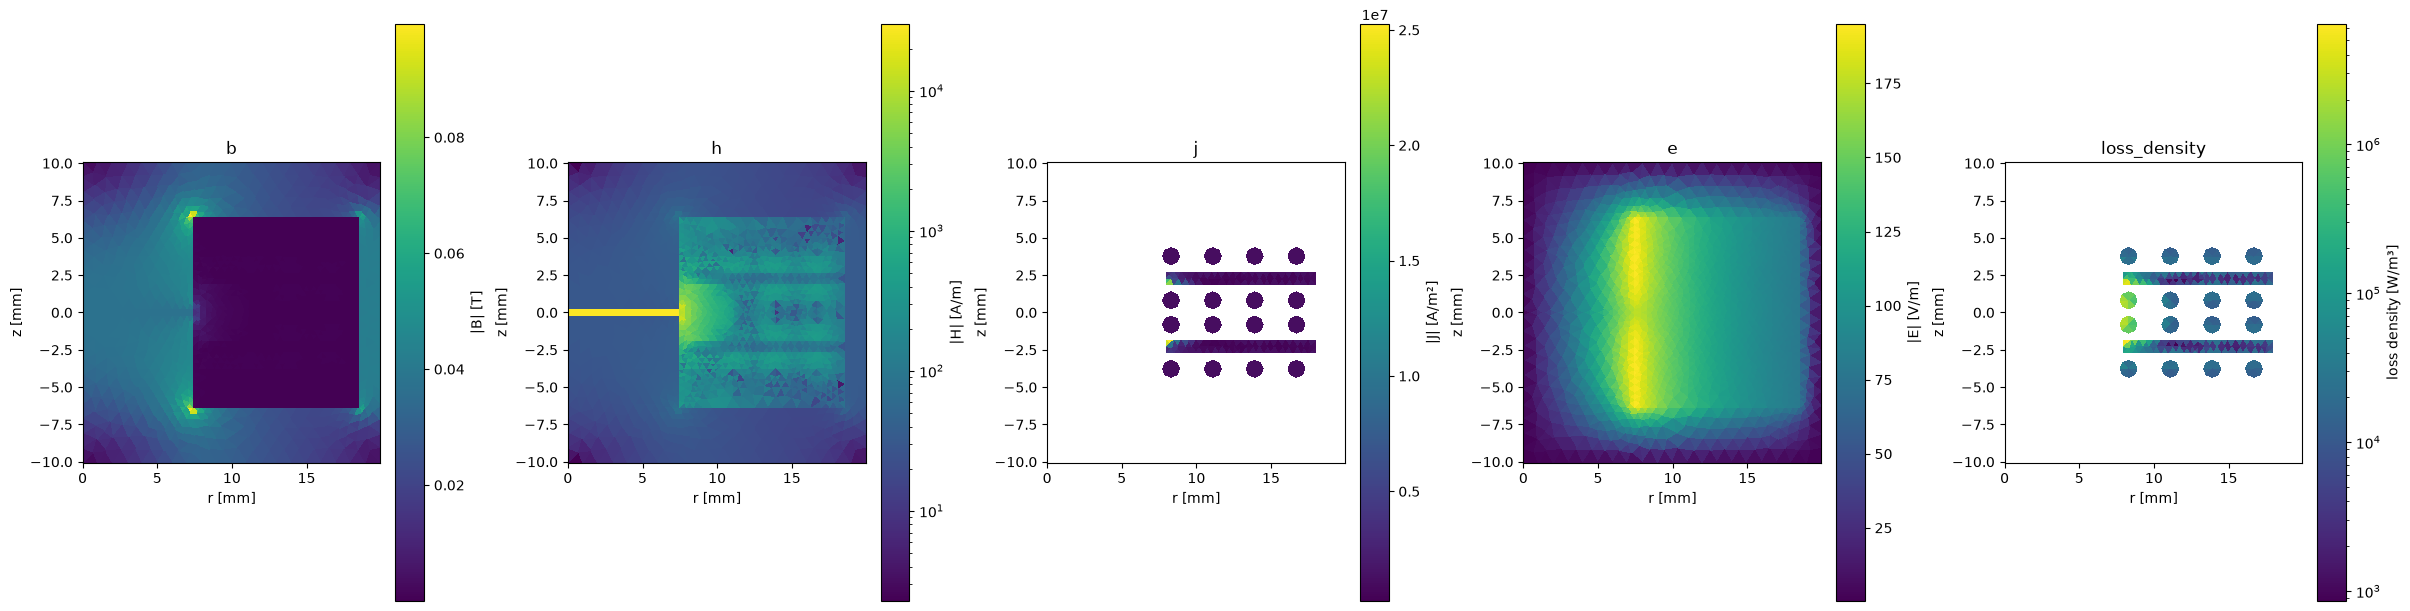

In [4]:
field_intensity_10 = magnetic_field_intensity(mesh, a_phi_10)
fig, axes = plt.subplots(1, 5, figsize=(24, 6), constrained_layout=True)
plot_requests = [
    (PhysicalField.B, {"a_phi": a_phi_10}),
    (PhysicalField.H, {"magnetic_field": field_intensity_10}),
    (PhysicalField.J, {"current_densities": densities_10, "a_phi": a_phi_10, "frequency": frequency}),
    (PhysicalField.E, {"a_phi": a_phi_10, "frequency": frequency}),
    (PhysicalField.LOSS_DENSITY, {"current_densities": densities_10, "magnetic_field": field_intensity_10, "a_phi": a_phi_10, "litz_properties": primary_litz_properties, "frequency": frequency}),
]
for axis, (physical_field, kwargs) in zip(axes.flat, plot_requests):
    scale = "log" if physical_field in {PhysicalField.H, PhysicalField.LOSS_DENSITY} else "linear"
    result_10.plot_physical_field(physical_field, ax=axis, color_scale=scale, **kwargs)
    axis.set_title(physical_field.value)
plt.show()